# Link Score Components

We look at raw components (land use diversity and POI diversity) before choosing normalization bounds, aggregation, and weights for the link score. We check how they're distributed, how many links have no POIs, how the components relate to each other, and how they depend on link length.

The goal is to settle open choices for the score:
- whether POI needs a floor
- richness bounds
- weights

<br><br>

## 0. Setup

### 0.1. Imports and Config

In [7]:
import numpy as np
import pandas as pd

from splendor.config import (
    CORRIDOR_RADIUS,
    ROAD_STRIP_RADIUS,
    STUDY_AREA,
    DIVERSITY_MEASURES,
    EXCLUDED_TYPES,
    RICHNESS_MIN_SHARE,
)
from splendor.io import load_network
from splendor.landuse.types import N_TYPES
from splendor.paths import network_path, link_diversity_path
from splendor.plotting.charts import plot_counts, plot_distributions, plot_against, plot_scatter_matrix

K = N_TYPES - len(EXCLUDED_TYPES) # Land use types the measures see
THEORETICAL_MAX = { # Reference lines only
    "shannon": np.log(K),
    "inverse_simpson": K,
    "richness": min(K, int(1 / RICHNESS_MIN_SHARE)), # At most 1 / threshold types can reach the threshold
}
TITLES = {m: m.replace("_", " ").capitalize() for m in DIVERSITY_MEASURES} | {"poi": "POI"}

### 0.2. Data

In [8]:
_, edges = load_network(network_path(STUDY_AREA))
diversity = pd.read_csv(link_diversity_path(STUDY_AREA, CORRIDOR_RADIUS, ROAD_STRIP_RADIUS))

links = edges[["edge_id", "length_m", "poi_diversity"]].merge(
    diversity, on="edge_id", how="inner", validate="one_to_one"
)
assert len(links) == len(edges) == len(diversity), "edge ids of network and diversity file don't match"

measure_columns = [f"diversity_{m}" for m in DIVERSITY_MEASURES]
component_columns = [*measure_columns, "poi_diversity"]

links[["length_m", *component_columns]].describe().round(3)

,length_m,diversity_shannon,diversity_inverse_simpson,diversity_richness,poi_diversity
count,638.000,638.000,638.000,638.000,638.000
mean,2274.977,0.857,1.991,2.011,0.978
std,1711.131,0.337,0.779,0.773,0.970
min,7.826,0.081,1.028,1.000,0.000
25%,1149.609,0.612,1.430,2.000,0.000
50%,2024.219,0.804,1.754,2.000,1.000
75%,3041.310,1.080,2.364,2.000,2.000
max,19793.209,1.931,5.989,5.000,3.000


<br><br>

## 1. POI Diversity

               links  share
poi_diversity              
0                247  0.387
1                218  0.342
2                113  0.177
3                 60  0.094


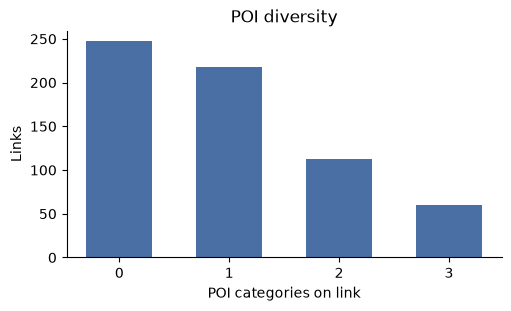

In [9]:
poi_counts = links["poi_diversity"].value_counts().reindex(range(4), fill_value=0)
print(pd.DataFrame({"links": poi_counts, "share": (poi_counts / len(links)).round(3)}))

plot_counts(links, "poi_diversity", range(4), "POI diversity", "POI categories on link");

<br><br>

## 2. Land Use Diversity

,min,max,theoretical_max
shannon,0.081,1.931,2.565
inverse_simpson,1.028,5.989,13.000
richness,1.000,5.000,10.000


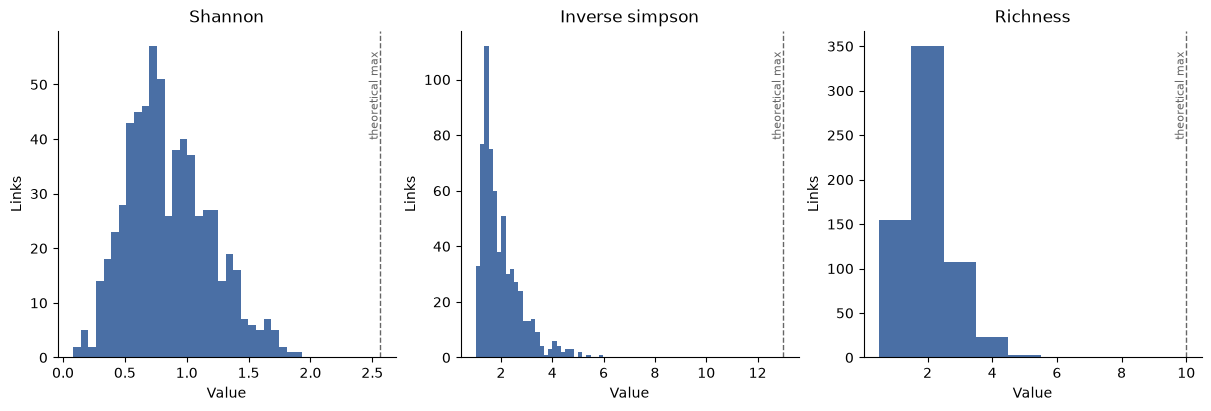

In [10]:
plot_distributions(
    links,
    measure_columns,
    titles=[TITLES[m] for m in DIVERSITY_MEASURES],
    references=[THEORETICAL_MAX[m] for m in DIVERSITY_MEASURES],
    reference_label="theoretical max",
    integer_columns=["diversity_richness"],
);

pd.DataFrame({
    "min": [links[f"diversity_{m}"].min() for m in DIVERSITY_MEASURES],
    "max": [links[f"diversity_{m}"].max() for m in DIVERSITY_MEASURES],
    "theoretical_max": [THEORETICAL_MAX[m] for m in DIVERSITY_MEASURES],
}, index=DIVERSITY_MEASURES).round(3)

<br><br>

## 3. Component Relations

                           diversity_shannon  diversity_inverse_simpson  \
diversity_shannon                       1.00                       0.97   
diversity_inverse_simpson               0.97                       1.00   
diversity_richness                      0.74                       0.80   
poi_diversity                           0.33                       0.36   

                           diversity_richness  poi_diversity  
diversity_shannon                        0.74           0.33  
diversity_inverse_simpson                0.80           0.36  
diversity_richness                       1.00           0.30  
poi_diversity                            0.30           1.00  


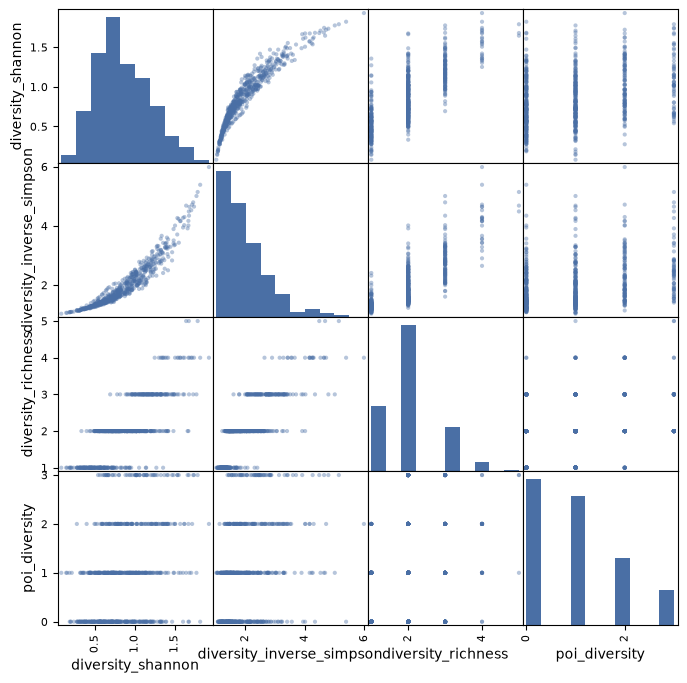

In [11]:
print(links[component_columns].corr(method="spearman").round(2))

plot_scatter_matrix(links, component_columns);

<br><br>

## 4. Length Dependence

diversity_shannon            0.13
diversity_inverse_simpson    0.03
diversity_richness          -0.05
poi_diversity                0.15
Name: length_m, dtype: float64


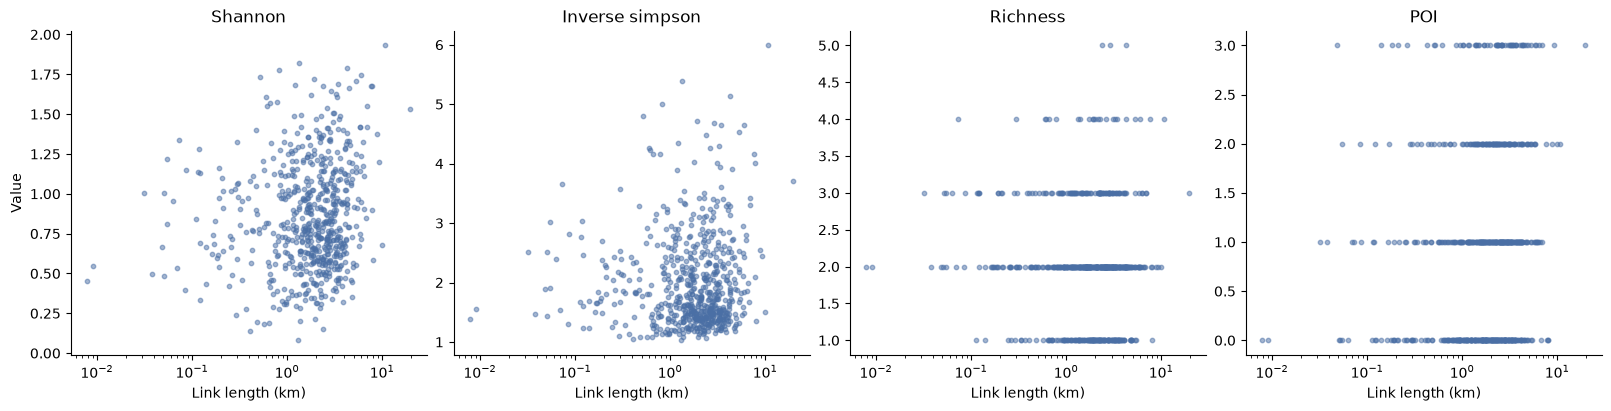

In [12]:
print(links[["length_m", *component_columns]].corr(method="spearman")["length_m"].drop("length_m").round(2))

plot_against(
    links,
    "length_m",
    component_columns,
    titles=[TITLES[m] for m in DIVERSITY_MEASURES] + [TITLES["poi"]],
    xlabel="Link length (km)",
    x_scale_factor=1 / 1000,
    xscale="log",
);

<br><br>

## 5. Conclusion

**POI**

39% of links have no POI categories (34% one, 18% two, 9% three). These links would all score 0 under a geometric mean without a floor, so whether POI gets a floor (bounds (-1, 3)) matters for a large part of the network.

**Land use range**

The data uses only part of the theoretical range (maximum 1.93 of 2.56 for Shannon, 6.0 of 13 for inverse Simpson, 5 of 10 for richness), and inverse Simpson is right-skewed. Normalization by theoretical bounds therefore compresses the scores into the lower part of [0, 1], while percentile and rank normalization spread them out.

**Relations**

Shannon and inverse Simpson rank links almost identically (Spearman 0.97); richness is coarser (0.74–0.80). POI is only weakly related to land use (0.30–0.36), i.e., the two components carry different information and the aggregation choice will matter.

**Length**

The components depend only weakly on link length (Spearman between -0.05 and 0.15), so the length bias seems small in the pilot. A few links are very short (down to about 8 m), so their corridors contain few pixels.